In [1]:
# 1. 加载文档
from langchain_community.document_loaders import WebBaseLoader
loader = WebBaseLoader(
    web_paths=("https://zh.wikipedia.org/wiki/黑神话：悟空",)
)
docs = loader.load()

USER_AGENT environment variable not set, consider setting it to identify your requests.


In [2]:
# 2. 文档分块
from langchain_text_splitters import RecursiveCharacterTextSplitter
text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
all_splits = text_splitter.split_documents(docs)

In [3]:
# 3. 设置嵌入模型
from langchain_openai import OpenAIEmbeddings
embeddings = OpenAIEmbeddings(
    model="bge-m3-mlx-4bit",
    openai_api_base="http://127.0.0.1:28080/v1",
    api_key="omlx",
    check_embedding_ctx_length=False
)

In [4]:
# 4. 创建向量存储
from langchain_core.vectorstores import InMemoryVectorStore
vector_store = InMemoryVectorStore(embeddings)
vector_store.add_documents(all_splits)

['1af23974-cd04-4844-b8bf-6c1716418e3a',
 'ba0aa315-8c12-4a60-a8de-5ea657e3019a',
 '58464f4c-0423-4c28-99a4-a78a98d11863',
 'bca63cac-48d5-4d70-b530-dba619868cdc',
 'a4517dc1-7dfb-40a5-90b9-54e30abf7d9d',
 '29e220bd-b52d-4b10-b711-354b8911bbd6',
 '46462bd8-8d22-4d76-b23a-5c94a2ad1eea',
 '4707d701-42b6-452a-986d-5d0c1228b766',
 '22e6e836-fefb-4de1-b897-24a50f012259',
 '8ce70248-4856-4c73-afec-d4d50af2ad15',
 'bb488e3f-d251-4c22-b420-010773954bfa',
 '60a8e849-a1b8-4e95-abf3-7048b72e4b7e',
 '4d7b3435-4435-4fcf-a903-30b98b413ccc',
 '6ff1a720-b8f5-4acc-bdda-dcd0d7efeb84',
 '5f637ecc-236d-489b-839b-7ed77ef1cbbd',
 '554e0425-9d21-4a73-b8ee-bd607053d316',
 '4a8f0fd5-f8c7-45db-a42c-b7cd4196caca',
 '7736eefb-b96f-451a-9001-774b4eeefa55',
 '38e9b58c-3085-4438-9528-f2d5bf0299c1',
 '99c5c896-66c9-45bd-a4ab-10f09795e29c',
 'faa28820-0396-472b-a3c5-023c3ad8d564',
 '7a1344ec-a6d0-4a00-a6f3-adf02714e333',
 'cc03e767-ce7c-4d1d-88d4-5125e10f0d7e',
 '002cbfe5-7fd2-4cd0-a360-b3a5fa54beb0',
 'df14d480-078e-

In [6]:
# 5. 定义RAG提示词
from langchain import hub
prompt = hub.pull("rlm/rag-prompt")

In [7]:
# 6. 定义应用状态
from typing import List
from typing_extensions import TypedDict
from langchain_core.documents import Document
class State(TypedDict):
    question: str
    context: List[Document]
    answer: str

In [8]:
# 7. 定义检索步骤
def retrieve(state: State):
    retrieved_docs = vector_store.similarity_search(state["question"])
    return {"context": retrieved_docs}

In [9]:
# 8. 定义生成步骤
def generate(state: State):
    from langchain_openai import ChatOpenAI
    llm = ChatOpenAI(
        model="deepseek-reasoner",  # DeepSeek API 支持的模型名称
        base_url="http://127.0.0.1:28080/v1",
        temperature=0.7,        # 控制输出的随机性(0-1之间,越大越随机)
        max_tokens=2048,        # 最大输出长度
        top_p=0.95,            # 控制输出的多样性(0-1之间)
        presence_penalty=0.0,   # 重复惩罚系数(-2.0到2.0之间)
        frequency_penalty=0.0,  # 频率惩罚系数(-2.0到2.0之间)
        api_key='omlx'  # 从环境变量加载API key
    )
    docs_content = "\n\n".join(doc.page_content for doc in state["context"])
    messages = prompt.invoke({"question": state["question"], "context": docs_content})
    response = llm.invoke(messages)
    return {"answer": response.content}

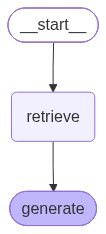

In [10]:
# 9. 构建和编译应用
from langgraph.graph import START, StateGraph
graph = (
    StateGraph(State)
    .add_sequence([retrieve, generate])
    .add_edge(START, "retrieve")
    .compile()
)

# 显示图结构
from IPython.display import Image, display
from langchain_core.runnables.graph import CurveStyle, MermaidDrawMethod, NodeStyles

display(
    Image(
        graph.get_graph().draw_mermaid_png(
            draw_method=MermaidDrawMethod.API,
        )
    )
)

In [11]:
# 10. 运行查询
question = "黑悟空有哪些游戏场景？"
response = graph.invoke({"question": question})
print(f"\n问题: {question}")
print(f"答案: {response['answer']}")


问题: 黑悟空有哪些游戏场景？
答案: 《黑神话：悟空》包含六个章节场景：“火照黑云”“风起黄昏”“夜生白露”“曲度紫鸳”“日落红尘”和“未竟”。游戏将多个中国文化和自然地标融入场景，包括重庆大足石刻、山西小西天、南禅寺、铁佛寺、广胜寺和鹳雀楼等。场景以线性推进为主，同时包含可探索区域、妖怪与头目战斗、神龛检查点以及多周目轮回玩法。
